# AwA2 — probing por cabeza sobre atributos (bloque 4, token CLS)

## 0. Configuración

In [1]:
# ======================================================================
MODELS = {"baseline": "vit-with-15-epochs-AwA2", "interpretable": "vit-with-15-epochs-interpretable-AwA2"}
BLOCK_IDX = 4             # 1-indexed, como en ablation.ipynb / head_specialization.ipynb
TOKEN = "cls"             # "cls" | "mean_patches" (promedio de la salida de la cabeza sobre los 64 parches)
N_FOLDS = 5
R2_THRESHOLD = 0.3        # "atributo bien predicho" por una cabeza (se reporta también un barrido)
BALACC_THRESHOLD = 0.75
SEED = 0
# ======================================================================

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.metrics import balanced_accuracy_score, r2_score
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

project_root = Path.cwd().resolve().parents[1]
sys.path.append(str(project_root))

from modules.datasets import AwA2Dataset
from modules.model import ViTForClassfication

torch.manual_seed(SEED)
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

EXPERIMENTS_DIR = project_root / "experimentation" / "experiments"
OUTPUT_DIR = EXPERIMENTS_DIR / "25092026_awa2_probing"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RUN_TAG = f"block{BLOCK_IDX}_{TOKEN}"


def save_fig(fig, stem):
    fig.savefig(OUTPUT_DIR / f"{stem}_{RUN_TAG}.png", dpi=150, bbox_inches="tight")

## 1. Datos y modelos

In [2]:
dataset = AwA2Dataset(image_size=32, root=str(project_root / "data" / "awa2"))
_, testloader, classes = dataset.get_loaders(batch_size=256)
attr_names = list(dataset.attribute_names)
n_attr = len(attr_names)

labels = dataset.testset.labels.numpy()
Y_cont = dataset.attributes_continuous[labels].numpy()   # (N, 85) en [0, 1]
Y_bin = dataset.attributes_binary[labels].numpy().astype(int)
print(f"test: {len(labels)} imágenes, {len(classes)} clases, {n_attr} atributos")


def load_model(name):
    exp_dir = EXPERIMENTS_DIR / name
    config = json.loads((exp_dir / "config.json").read_text())
    metrics = json.loads((exp_dir / "metrics.json").read_text())
    assert not config["use_faster_attention"], "se asume block.attention.heads como submódulos separados"
    model = ViTForClassfication(config)
    model.load_state_dict(torch.load(exp_dir / "model_final.pt", map_location="cpu"))
    return model.to(device).eval(), config, metrics


models = {key: load_model(name) for key, name in MODELS.items()}
n_heads = models["baseline"][1]["num_attention_heads"]
block_idx0 = BLOCK_IDX - 1
head_labels = [f"head {h + 1}" for h in range(n_heads)]

test: 7468 imágenes, 50 clases, 85 atributos


## 2. Extracción de la salida de cada cabeza

In [3]:
@torch.no_grad()
def extract_head_outputs(model):
    captured = {}
    heads = model.encoder.blocks[block_idx0].attention.heads
    hooks = [head.register_forward_hook(lambda _m, _i, out, h=h: captured.__setitem__(h, out[0]))
             for h, head in enumerate(heads)]
    feats, preds = [], []
    try:
        for images, _, _ in testloader:
            logits, _ = model(images.to(device))
            per_head = torch.stack([captured[h] for h in range(n_heads)], dim=1)   # (B, H, T, d)
            per_head = per_head[:, :, 0] if TOKEN == "cls" else per_head[:, :, 1:].mean(dim=2)
            feats.append(per_head.cpu())
            preds.append(logits.argmax(-1).cpu())
    finally:
        for hook in hooks:
            hook.remove()
    return torch.cat(feats).numpy(), torch.cat(preds).numpy()


head_feats = {}
for key, (model, _, metrics) in models.items():
    head_feats[key], preds = extract_head_outputs(model)
    acc = (preds == labels).mean()
    print(f"{key:>13}: feats {head_feats[key].shape}, accuracy recomputada {acc:.4f} "
          f"(metrics.json: {metrics['accuracy']:.4f})")

     baseline: feats (7468, 4, 12), accuracy recomputada 0.3091 (metrics.json: 0.3091)
interpretable: feats (7468, 4, 12), accuracy recomputada 0.2957 (metrics.json: 0.2957)


## 3. Probing lineal por cabeza × atributo

In [7]:
folds_image = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(labels, labels))
folds_class = list(GroupKFold(N_FOLDS).split(labels, labels, groups=labels))   # clases no vistas


def probe_r2(X, Y, folds):
    """R² out-of-fold por atributo (Ridge multi-salida, alpha elegido por atributo dentro de cada fold)."""
    pred = np.zeros_like(Y)
    for tr, te in folds:
        probe = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13), alpha_per_target=True))
        pred[te] = probe.fit(X[tr], Y[tr]).predict(X[te])
    return r2_score(Y, pred, multioutput="raw_values")


def probe_balacc(X, Yb, folds):
    """Balanced accuracy out-of-fold por atributo binarizado (logística con class_weight balanceado)."""
    scores = np.full(Yb.shape[1], np.nan)
    for a in range(Yb.shape[1]):
        y = Yb[:, a]
        if y.min() == y.max():
            continue
        pred = np.zeros_like(y)
        for tr, te in folds:
            probe = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000))
            pred[te] = probe.fit(X[tr], y[tr]).predict(X[te])
        scores[a] = balanced_accuracy_score(y, pred)
    return scores


r2, r2_unseen, balacc, r2_block = {}, {}, {}, {}
for key, feats in head_feats.items():
    r2[key] = np.stack([probe_r2(feats[:, h], Y_cont, folds_image) for h in range(n_heads)])          # (H, 85)
    r2_unseen[key] = np.stack([probe_r2(feats[:, h], Y_cont, folds_class) for h in range(n_heads)])
    balacc[key] = np.stack([probe_balacc(feats[:, h], Y_bin, folds_image) for h in range(n_heads)])
    # Referencia: probe sobre las 4 cabezas concatenadas (48-d) — techo de lo decodificable en el bloque.
    r2_block[key] = probe_r2(feats.reshape(len(feats), -1), Y_cont, folds_image)
    print(f"{key:>13}: R² medio {r2[key].mean():.3f} | clases no vistas {r2_unseen[key].mean():.3f} | "
          f"bal.acc media {np.nanmean(balacc[key]):.3f} | bloque completo {r2_block[key].mean():.3f}")

for key in MODELS:
    pd.DataFrame(r2[key], index=head_labels, columns=attr_names).to_csv(OUTPUT_DIR / f"r2_{key}_{RUN_TAG}.csv")
    pd.DataFrame(r2_unseen[key], index=head_labels, columns=attr_names).to_csv(OUTPUT_DIR / f"r2_unseen_classes_{key}_{RUN_TAG}.csv")
    pd.DataFrame(balacc[key], index=head_labels, columns=attr_names).to_csv(OUTPUT_DIR / f"balacc_{key}_{RUN_TAG}.csv")

     baseline: R² medio 0.079 | clases no vistas -0.026 | bal.acc media 0.634 | bloque completo 0.160
interpretable: R² medio 0.052 | clases no vistas -0.040 | bal.acc media 0.609 | bloque completo 0.128


## 4. Heatmaps cabeza × atributo

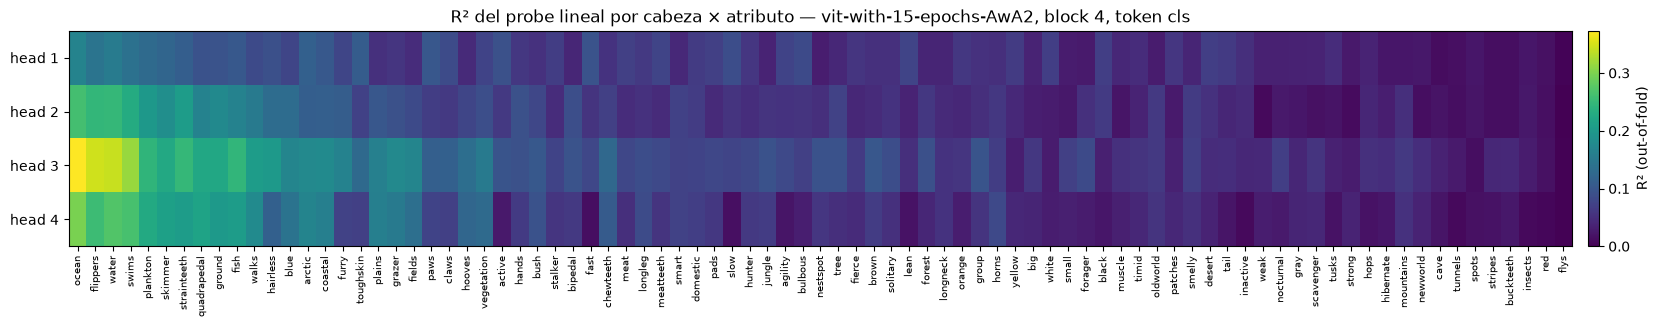

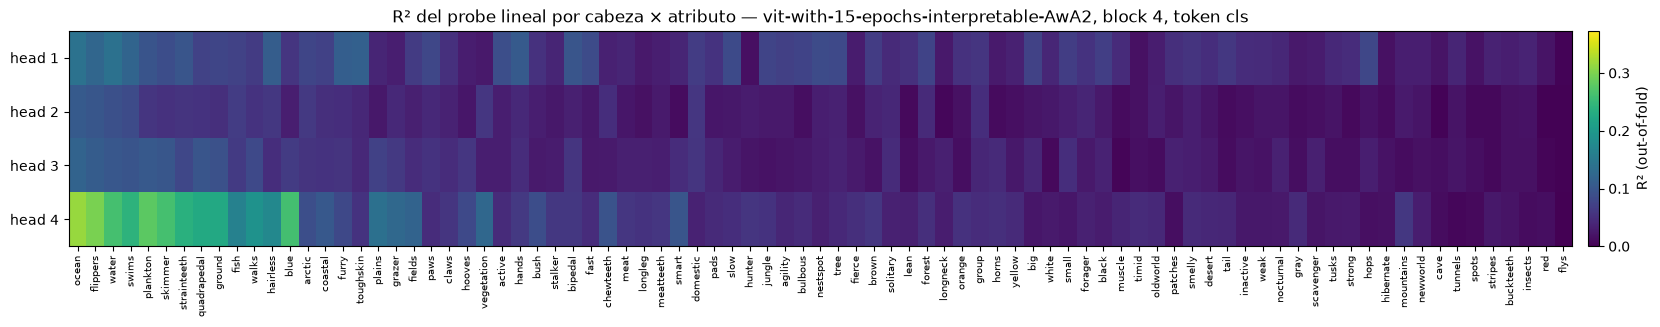

In [8]:
attr_order = np.argsort(-r2_block["baseline"])
vmax = max(r2[k].max() for k in MODELS)

for key in MODELS:
    fig, ax = plt.subplots(figsize=(20, 2.8))
    im = ax.imshow(np.clip(r2[key][:, attr_order], 0, None), cmap="viridis", vmin=0, vmax=vmax, aspect="auto")
    ax.set_yticks(range(n_heads)); ax.set_yticklabels(head_labels)
    ax.set_xticks(range(n_attr)); ax.set_xticklabels([attr_names[i] for i in attr_order], rotation=90, fontsize=7)
    ax.set_title(f"R² del probe lineal por cabeza × atributo — {MODELS[key]}, block {BLOCK_IDX}, token {TOKEN}")
    fig.colorbar(im, ax=ax, label="R² (out-of-fold)", fraction=0.02, pad=0.01)
    save_fig(fig, f"r2_heatmap_{key}")
    plt.show()

## 5. Métricas de especialización

In [9]:
from modules.similarity import offdiag_mean, pairwise_similarity_matrix


def jaccard_matrix(masks):
    H = masks.shape[0]
    M = np.eye(H)
    for i in range(H):
        for j in range(i + 1, H):
            union = (masks[i] | masks[j]).sum()
            M[i, j] = M[j, i] = (masks[i] & masks[j]).sum() / union if union else np.nan
    return M


def offdiag_mean(M):
    iu = np.triu_indices(M.shape[0], k=1)
    return float(np.nanmean(M[iu]))


def specialization_metrics(scores, threshold):
    """scores: (H, n_attr), mayor = mejor. Devuelve dict de métricas escalares."""
    pos = np.clip(np.nan_to_num(scores, nan=0.0), 0, None)
    good = scores > threshold                       # (H, n_attr)
    covered = good.any(axis=0)
    p = pos / np.where(pos.sum(0) > 0, pos.sum(0), 1)
    entropy = -(p * np.log(np.where(p > 0, p, 1))).sum(0) / np.log(scores.shape[0])
    return {
        "cobertura (nº atributos)": int(covered.sum()),
        "cabezas por atributo cubierto": float(good[:, covered].sum(0).mean()) if covered.any() else np.nan,
        "Jaccard medio entre cabezas": offdiag_mean(jaccard_matrix(good)),
        "entropía normalizada entre cabezas": float(entropy[covered].mean()) if covered.any() else np.nan,
        **{f"nº atributos > τ, {head_labels[h]}": int(good[h].sum()) for h in range(scores.shape[0])},
    }


cosine = {k: pairwise_similarity_matrix(np.clip(r2[k], 0, None), "cosine") for k in MODELS}
pearson = {k: pairwise_similarity_matrix(np.clip(r2[k], 0, None), "pearson") for k in MODELS}

rows = {}
for key, (_, _, metrics) in models.items():
    rows[key] = {
        "accuracy (test)": metrics["accuracy"],
        "R² medio (cabeza × atributo)": float(r2[key].mean()),
        "R² máx. por atributo, media": float(r2[key].max(0).mean()),
        "R² bloque completo (48-d), media": float(r2_block[key].mean()),
        "R² medio, clases no vistas": float(r2_unseen[key].mean()),
        "bal.acc media (binarizado)": float(np.nanmean(balacc[key])),
        f"cobertura bal.acc > {BALACC_THRESHOLD}": int((balacc[key] > BALACC_THRESHOLD).any(0).sum()),
        "coseno medio entre vectores de R²": offdiag_mean(cosine[key]),
        "Pearson medio entre vectores de R²": offdiag_mean(pearson[key]),
        **{f"[τ={R2_THRESHOLD}] {m}": v for m, v in specialization_metrics(r2[key], R2_THRESHOLD).items()},
        **{f"[clases no vistas, τ={R2_THRESHOLD}] {m}": v
           for m, v in specialization_metrics(r2_unseen[key], R2_THRESHOLD).items() if not m.startswith("nº")},
    }

summary = pd.DataFrame(rows)
summary["Δ (interp. − baseline)"] = summary["interpretable"] - summary["baseline"]
summary.to_csv(OUTPUT_DIR / f"summary_{RUN_TAG}.csv")
summary.round(3)

/var/folders/sx/_3f9ftxx24q3hbz_25d1xrjh0000gn/T/ipykernel_87319/2489673987.py:16: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(M[iu]))


,baseline,interpretable,Δ (interp. − baseline)
accuracy (test),0.309,0.296,-0.013
R² medio (cabeza × atributo),0.079,0.052,-0.027
"R² máx. por atributo, media",0.108,0.091,-0.017
"R² bloque completo (48-d), media",0.160,0.128,-0.033
"R² medio, clases no vistas",-0.026,-0.040,-0.014
bal.acc media (binarizado),0.634,0.609,-0.025
cobertura bal.acc > 0.75,12.000,5.000,-7.000
coseno medio entre vectores de R²,0.951,0.904,-0.047
Pearson medio entre vectores de R²,0.881,0.744,-0.137
[τ=0.3] cobertura (nº atributos),4.000,1.000,-3.000


### Barrido de umbral τ

In [10]:
sweep = []
for tau in (0.1, 0.2, 0.3, 0.4, 0.5):
    for key in MODELS:
        m = specialization_metrics(r2[key], tau)
        sweep.append({"τ": tau, "modelo": key, **{k: v for k, v in m.items() if not k.startswith("nº")}})
sweep = pd.DataFrame(sweep).set_index(["τ", "modelo"])
sweep.to_csv(OUTPUT_DIR / f"threshold_sweep_{RUN_TAG}.csv")
sweep.round(3)

/var/folders/sx/_3f9ftxx24q3hbz_25d1xrjh0000gn/T/ipykernel_87319/2489673987.py:16: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(M[iu]))


cobertura (nº atributos)  cabezas por atributo cubierto  \
τ   modelo                                                                   
0.1 baseline                             27                          2.852   
    interpretable                        21                          1.476   
0.2 baseline                             12                          2.167   
    interpretable                        10                          1.000   
0.3 baseline                              4                          1.000   
    interpretable                         1                          1.000   
0.4 baseline                              0                            NaN   
    interpretable                         0                            NaN   
0.5 baseline                              0                            NaN   
    interpretable                         0                            NaN   

                   Jaccard medio entre cabezas  \
τ   modelo                                       
0.1 baseline                             0.590   
    interpretable                        0.204   
0.2 baseline                             0.287   
    interpretable                        0.000   
0.3 baseline                             0.000   
    interpretable                        0.000   
0.4 baseline                               NaN   
    interpretable                          NaN   
0.5 baseline                               NaN   
    interpretable                          NaN   

                   entropía normalizada entre cabezas  
τ   modelo                                             
0.1 baseline                                    0.968  
    interpretable                               0.902  
0.2 baseline                                    0.972  
    interpretable                               0.885  
0.3 baseline                                    0.972  
    interpretable                               0.921  
0.4 baseline                                      NaN  
    interpretable                                 NaN  
0.5 baseline                                      NaN  
    interpretable                                 NaN

## 6. Similitud entre cabezas (vectores de R² por atributo)

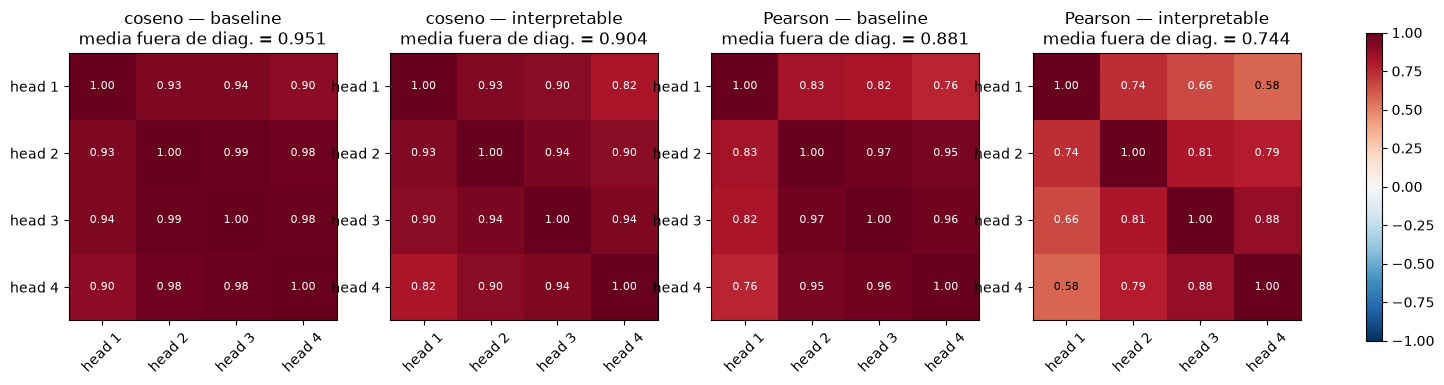

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (title, mats, key) in zip(axes, [("coseno", cosine, "baseline"), ("coseno", cosine, "interpretable"),
                                         ("Pearson", pearson, "baseline"), ("Pearson", pearson, "interpretable")]):
    M = mats[key]
    im = ax.imshow(M, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(n_heads)); ax.set_xticklabels(head_labels, rotation=45)
    ax.set_yticks(range(n_heads)); ax.set_yticklabels(head_labels)
    for i in range(n_heads):
        for j in range(n_heads):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(M[i, j]) > 0.6 else "black")
    ax.set_title(f"{title} — {key}\nmedia fuera de diag. = {offdiag_mean(M):.3f}")
fig.colorbar(im, ax=axes, fraction=0.015)
save_fig(fig, "r2_head_similarity")
plt.show()

## 7. Atributos mejor predichos por cada cabeza

In [12]:
for key in MODELS:
    print(f"=== {MODELS[key]} ===")
    best = r2[key].argmax(0)
    for h in range(n_heads):
        won = [a for a in np.argsort(-r2[key][h]) if best[a] == h and r2[key][h, a] > R2_THRESHOLD]
        print(f"  {head_labels[h]} ({len(won):2d}): " + ", ".join(f"{attr_names[a]} {r2[key][h, a]:.2f}" for a in won[:12]))
    print()

=== vit-with-15-epochs-AwA2 ===
  head 1 ( 0): 
  head 2 ( 0): 
  head 3 ( 4): ocean 0.37, flippers 0.35, water 0.34, swims 0.32
  head 4 ( 0): 

=== vit-with-15-epochs-interpretable-AwA2 ===
  head 1 ( 0): 
  head 2 ( 0): 
  head 3 ( 0): 
  head 4 ( 1): ocean 0.32



## 8. Mejor cabeza por atributo — baseline vs. penalizado

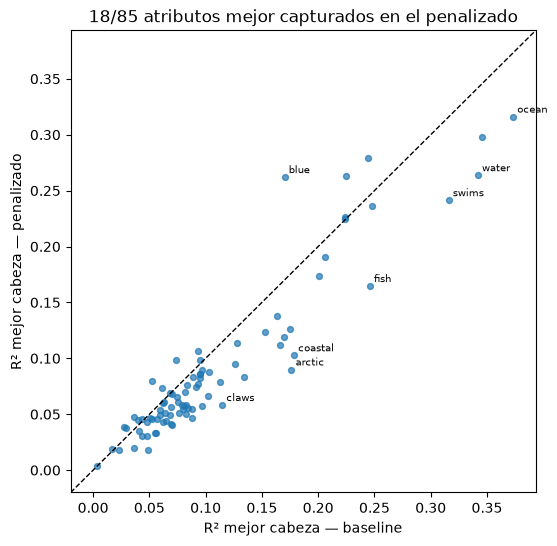

In [13]:
fig, ax = plt.subplots(figsize=(6, 6))
xb, yi = r2["baseline"].max(0), r2["interpretable"].max(0)
ax.scatter(xb, yi, s=18, alpha=0.7)
lim = [min(xb.min(), yi.min(), 0) - 0.02, max(xb.max(), yi.max()) + 0.02]
ax.plot(lim, lim, "k--", lw=1)
for a in np.argsort(-np.abs(yi - xb))[:8]:
    ax.annotate(attr_names[a], (xb[a], yi[a]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("R² mejor cabeza — baseline"); ax.set_ylabel("R² mejor cabeza — penalizado")
ax.set_title(f"{(yi > xb).sum()}/{n_attr} atributos mejor capturados en el penalizado")
save_fig(fig, "best_head_r2_scatter")
plt.show()